# DBSCAN

The variables that were chosen for DBSCAN are `GameWeight`, `MinPlayers`, `MaxPlayers_log`, `AgeRec`, `NumOwned_log` and `AvgPlaytime_log`

A Robust Scaler is used as it gave better results and separations in clusters.

In [109]:
import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler

df_raw = pd.read_csv("../01 - DataPreparation/df_prepared.csv")

print("Shape:", df_raw.shape)
print(df_raw.dtypes.value_counts())

# DBSCAN features (start continuous-heavy & avoid Cat:* for distance)
dbscan_features = [
    "GameWeight",
    # "MinPlayers", 
    "MaxPlayers_log",
    "AgeRec",
    "NumOwned_log",
    "AvgPlaytime_log"
]

# ensure columns exist
missing_cols = [c for c in dbscan_features if c not in df_raw.columns]
if missing_cols:
    raise ValueError(f"Missing columns in df_prepared.csv: {missing_cols}")

X = df_raw[dbscan_features].copy()

# 4) scale which is critical for distance-based methods
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

print("\nScaled shape:", X_scaled.shape)
print("Scaled mean (first 5 dims):", X_scaled.mean(axis=0)[:5])
print("Scaled std  (first 5 dims):", X_scaled.std(axis=0)[:5])

Shape: (20573, 30)
int64      19
float64    10
object      1
Name: count, dtype: int64

Scaled shape: (20573, 5)
Scaled mean (first 5 dims): [0.02797507 0.23013361 0.04025361 0.12766862 0.01593087]
Scaled std  (first 5 dims): [0.66783102 1.4335608  0.66437744 0.76339728 0.82638791]


## Choosing ε using the k-distance plot
DBSCAN has two key parameters:
- ε (epsilon): neighborhood radius
- MinPts: minimum number of points to form a dense region

From the lecture:
- A good ε separates dense regions (clusters) from sparse regions (noise)
- This is typically done using a k-distance plot, where: k = MinPts − 1, we sort distances to the k-th nearest neighbor, and we look for a clear “elbow” as a sign for optimal ε

This step is mandatory and explicitly recommended in DBSCAN theory

choosing MinPts: MinPts ≥ d + 1, where d = number of dimensions (general rule of thumb). we have 5 features so we use MinPts = 6 (for now)

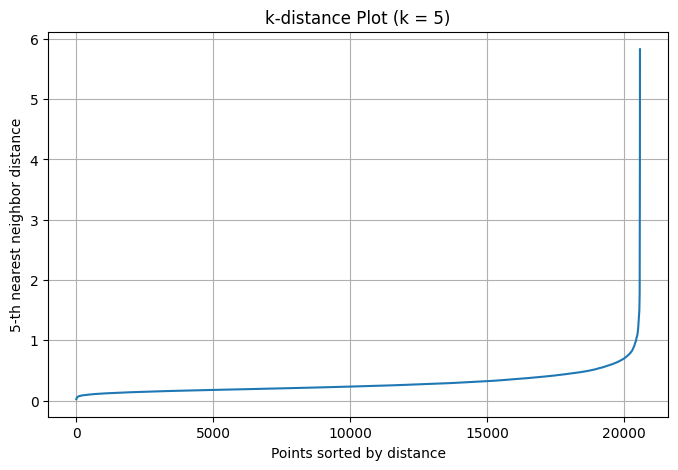

In [110]:
min_pts = 6
k = min_pts - 1

# fit nearest neighbors
nbrs = NearestNeighbors(n_neighbors=k)
nbrs.fit(X_scaled)

# 3) find distances to k-th nearest neighbor
distances, _ = nbrs.kneighbors(X_scaled)

# take the distance to the k-th neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{k}-th nearest neighbor distance")
plt.title(f"k-distance Plot (k = {k})")
plt.grid(True)
plt.show()

In [111]:
percentiles = [80, 90, 98, 99]
percentile_values = np.percentile(k_distances, percentiles)

print(percentile_values)

[0.3713842  0.47909891 0.75973876 0.90946614]


The percentile values of k_distances indicates that "exploring" eps values between 0.4 and 0.7 could show the best eps for interpretability and clustering results. 

## Fit DBSCAN

In [ ]:


eps_range = np.arange(0.4, 0.7, 0.05)

print("eps    | clusters | noise pts | noise % | largest cluster | largest % | silhouette (no-noise)")
print("-" * 105)

for eps in eps_range:
    db = DBSCAN(eps=eps, min_samples=14)
    labels = db.fit_predict(X_scaled)

    # clusters/noise
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)
    noise_pct = n_noise / len(labels) * 100

    # largest cluster (excluding noise)
    if n_clusters > 0:
        cluster_labels = labels[labels != -1]
        largest_cluster_size = np.max(np.bincount(cluster_labels))
        largest_pct = largest_cluster_size / len(labels) * 100
    else:
        largest_cluster_size = 0
        largest_pct = 0.0

    # silhouette (excluding noise; needs >=2 clusters and >=2 samples)
    sil = np.nan
    mask = labels != -1
    if n_clusters >= 2 and np.sum(mask) >= 2:
        sil = silhouette_score(X_scaled[mask], labels[mask], metric="euclidean")

    sil_str = f"{sil: .3f}" if np.isfinite(sil) else "   NaN"
    print(
        f"{eps:.2f}   | {n_clusters:8d} | {n_noise:9d} | {noise_pct:6.1f}% | "
        f"{largest_cluster_size:15d} | {largest_pct:8.1f}% | {sil_str}"
    )


eps    | clusters | noise pts | noise % | largest cluster | largest % | silhouette (no-noise)
---------------------------------------------------------------------------------------------------------
0.40   |        8 |      4144 |   20.1% |            6110 |     29.7% | -0.000
0.45   |        9 |      2919 |   14.2% |            6285 |     30.5% | -0.009
0.50   |        5 |      2146 |   10.4% |            7904 |     38.4% |  0.044
0.55   |        6 |      1601 |    7.8% |           14637 |     71.1% | -0.046
0.60   |        7 |      1172 |    5.7% |           14889 |     72.4% | -0.057
0.65   |        5 |       802 |    3.9% |           15156 |     73.7% |  0.148


An eps value of 0.65 looks promising. Silhouette is decent, but a large cluster always appears, probably indicating that clusters have different densities and there is now way to create a significant distinction between them using DBSCAN.

In [107]:
df_raw

,BGGId,GameWeight,MinPlayers,MaxPlayers,NumOwned,NumWant,NumAlternates,NumExpansions,NumImplementations,IsReimplementation,...,AvgPlaytime,AgeRec,NumOwned_log,NumAlternates_log,NumExpansions_log,NumImplementations_log,NumWant_log,AvgPlaytime_log,MaxPlayers_log,cluster_DBSCAN
0,17755,1.0000,2,6,145,1,18,0,2,1,...,20.0,5.500000,4.983607,2.944439,0.000000,1.098612,0.693147,3.044522,1.945910,0
1,14765,2.6000,4,4,25,2,0,0,0,0,...,10.0,8.308707,3.258097,0.000000,0.000000,0.000000,1.098612,2.397895,1.609438,0
2,17183,2.0000,2,4,20,0,9,0,0,0,...,60.0,11.000000,3.044522,2.302585,0.000000,0.000000,0.000000,4.110874,1.609438,0
3,2294,1.1379,1,8,1848,5,2,0,0,0,...,20.0,7.166667,7.522400,1.098612,0.000000,0.000000,1.791759,3.044522,2.197225,0
4,140,1.1582,3,8,15115,75,19,1,1,1,...,60.0,7.421053,9.623509,2.995732,0.693147,0.693147,4.330733,4.110874,2.197225,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20568,310192,2.0455,1,5,2386,74,0,1,0,0,...,25.0,7.416667,7.777793,0.000000,0.693147,0.000000,4.317488,3.258097,1.791759,0
20569,319579,1.1111,1,5,761,131,0,0,0,0,...,25.0,7.025166,6.635947,0.000000,0.000000,0.000000,4.882802,3.258097,1.791759,0
20570,307386,2.5000,1,4,849,18,3,1,0,0,...,67.5,10.135379,6.745236,1.386294,0.693147,0.000000,2.944439,4.226834,1.609438,0
20571,322560,2.0000,1,2,204,20,0,0,1,1,...,22.5,12.000000,5.323010,0.000000,0.000000,0.693147,3.044522,3.157000,1.098612,1


In [112]:
db = DBSCAN(eps=0.65, min_samples=14)
labels = db.fit_predict(X_scaled)

df_raw['cluster_DBSCAN'] = labels

df_raw[['BGGId','cluster_DBSCAN']].to_csv('dbscan_labels.csv')

## Cluster Profiling

In [116]:
# Assuming df_raw is already loaded and has the cluster_DBSCAN column
# Define continuous features (numerical columns for median)
continuous = ['GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned', 'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations', 'Age', 'AvgPlaytime', 'AgeRec']

# Define binary features (for mean, which gives proportion)
binary = ['IsReimplementation', 'Kickstarted'] + [col for col in df_raw.columns if col.startswith('Cat:')]

# Compute medians for continuous features grouped by cluster_DBSCAN
cluster_profile_continuous = df_raw.groupby('cluster_DBSCAN')[continuous].median()

# Compute means for binary features grouped by cluster_DBSCAN
cluster_profile_binary = df_raw.groupby('cluster_DBSCAN')[binary].mean()

# Combine into a single dataframe
cluster_profile = pd.concat([cluster_profile_continuous, cluster_profile_binary], axis=1)


clusters_sizes = df_raw["cluster_DBSCAN"].value_counts().sort_index()
profile = cluster_profile_continuous.join(cluster_profile_binary)
cluster_profile.insert(0, "n", clusters_sizes)
cluster_profile.insert(1, "pct", (clusters_sizes / len(df_raw)).round(3))
# Print the dataframe
cluster_profile

,n,pct,GameWeight,MinPlayers,MaxPlayers,NumOwned,NumWant,NumAlternates,NumExpansions,NumImplementations,...,IsReimplementation,Kickstarted,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
cluster_DBSCAN,,,,,,,,,,,,,,,,,,,,,
-1,802,0.039,1.9129,2.0,10.0,366.0,9.0,0.0,0.0,0.0,...,0.144638,0.135910,0.079800,0.059850,0.203242,0.054863,0.012469,0.028678,0.134663,0.023691
0,15156,0.737,1.8333,2.0,5.0,365.0,9.0,0.0,0.0,0.0,...,0.118699,0.178081,0.064661,0.132819,0.056479,0.136909,0.009303,0.033980,0.033122,0.050409
1,4023,0.196,2.4000,2.0,2.0,309.0,10.0,0.0,0.0,0.0,...,0.121551,0.090480,0.035546,0.056426,0.518270,0.038777,0.035297,0.109123,0.000994,0.010937
2,318,0.015,2.1127,1.0,1.0,307.5,15.0,0.0,0.0,0.0,...,0.088050,0.119497,0.088050,0.025157,0.424528,0.012579,0.000000,0.009434,0.000000,0.000000
3,211,0.010,2.4802,2.0,3.0,302.0,12.0,0.0,0.0,0.0,...,0.047393,0.175355,0.028436,0.080569,0.483412,0.018957,0.018957,0.104265,0.000000,0.000000
4,63,0.003,1.1429,2.0,99.0,348.0,4.0,1.0,0.0,0.0,...,0.095238,0.047619,0.000000,0.000000,0.031746,0.015873,0.000000,0.000000,0.158730,0.031746


## Interpretations

### Cluster 0

* 15156 records (76.7%)
* AgeRec ≈ 9.8+
* GameWeight ≈ 1.83 (light–mid complexity)
* Players: up to ~5
* AvgPlaytime ≈ 40 minutes
* No strong single-category dominance (broad mainstream mix)

Broad-appeal hobby/casual titles: approachable rules, standard group sizes, and medium session length. This is the densest “default” region in the DBSCAN feature space.

Representative examples: Ticket to Ride, Love Letter.

---

### Cluster 1

* 4023 records (20.4%)
* AgeRec ≈ 12+
* GameWeight ≈ 2.40 (heavier)
* Players: almost exclusively 2
* AvgPlaytime ≈ 60 minutes
* War-leaning flavor compared to Cluster 0 (but not the main driver)

More demanding head-to-head games: higher cognitive load, older target age, and longer sessions than the mainstream cluster, typically suited to experienced players.

Representative examples: Hive, Battleship.

---

### Cluster 2

* 318 records (1.6%)
* AgeRec ≈ 12+
* GameWeight ≈ 2.11 (mid-heavy)
* Players: solo (max = 1)
* AvgPlaytime ≈ 45 minutes

A distinct solo pocket defined primarily by the player-count constraint: mid-to-heavy decision-making in a moderate playtime window.

Representative examples: Friday, Under Falling Skies.

---

### Cluster 3

* 211 records (1.1%)
* AgeRec ≈ 12+
* GameWeight ≈ 2.48 (very heavy)
* Players: 2–3
* AvgPlaytime ≈ 67.5 minutes (longest)

Small-group “serious” games: a step up from the typical 2-player heavy cluster, combining higher weight with longer playtime while staying in a tight 2–3 player band.

Representative examples: Greenland, Great War Commander.

---

### Cluster 4

* 63 records (0.3%)
* AgeRec ≈ 9.6+
* GameWeight ≈ 1.14 (very light)
* Players: extremely high (max ≈ 99)
* AvgPlaytime ≈ 20 minutes (shortest)

Large-group / event-scale games: very light rules, short rounds, and crowd-sized player counts. This cluster is mostly separated by the extreme MaxPlayers dimension.


Representative examples: Banned Words, Game of Phones.


## Rating distribution per DBSCAN cluster
DBSCAN is unsupervised, so we need an external variable to validate whether clusters are meaningful. Checking how ratings distribute across DBSCAN clusters tells us whether DBSCAN is capturing quality-related structure.

### rating count per cluster

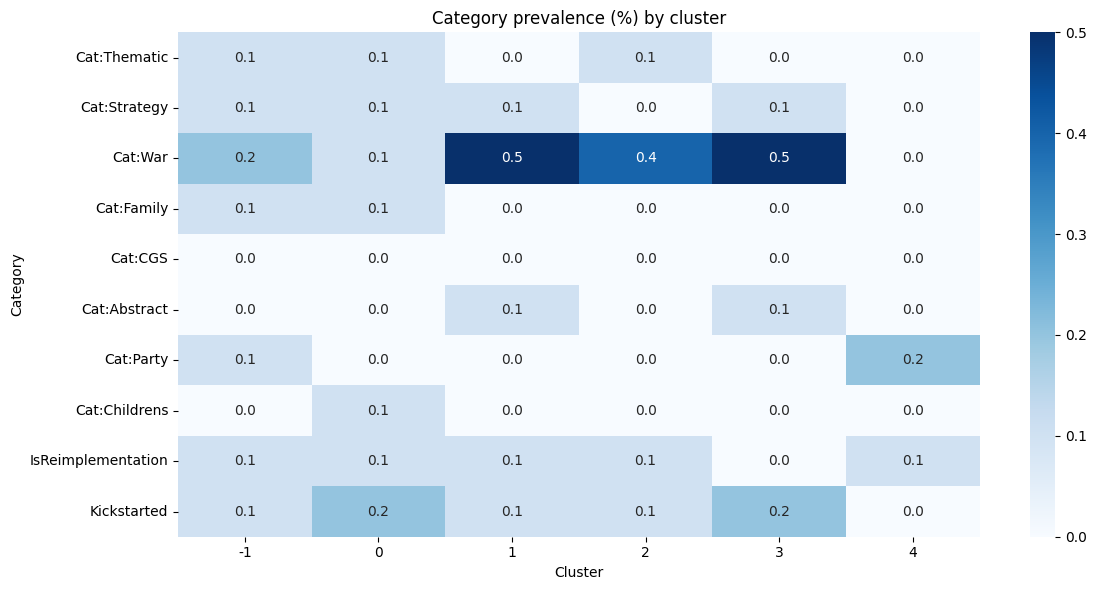

In [117]:
cluster_cat = cluster_profile[binary_feats]

plt.figure(figsize=(12, 6))
sns.heatmap(
    cluster_cat.T.round(1),
    annot=True,
    fmt=".1f",
    cmap="Blues"
)
plt.title("Category prevalence (%) by cluster")
plt.xlabel("Cluster")
plt.ylabel("Category")
plt.tight_layout()
plt.show()



### rating proportion per cluster

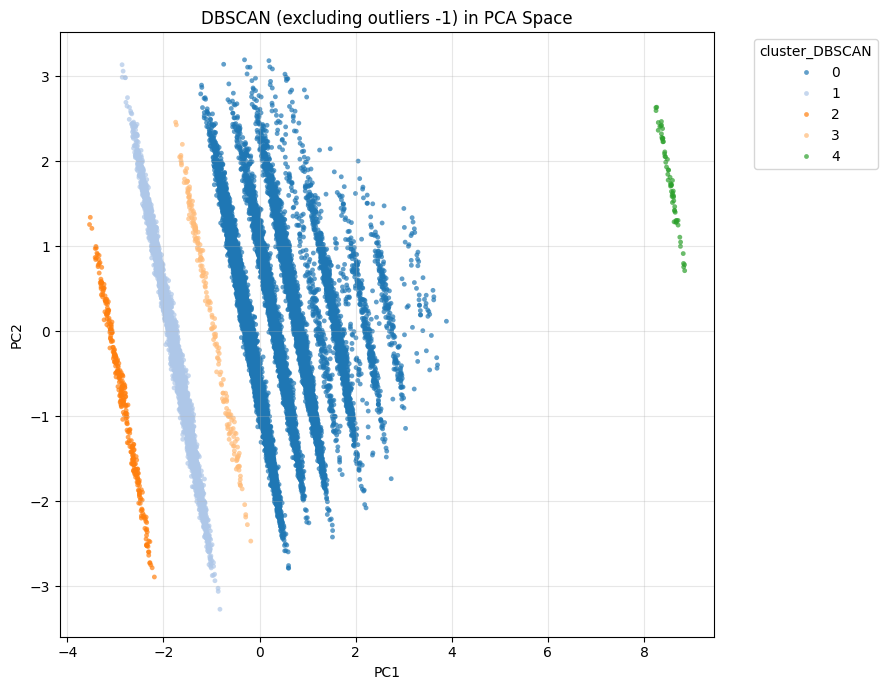

Explained variance by PC1 and PC2: [0.513 0.278]


In [118]:


# dfc already has cluster_DBSCAN, and X_scaled is aligned with dfc
mask_core = df_raw["cluster_DBSCAN"] != -1

# PCA on full data (stable view of the space)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df_pca = df_raw.copy()
df_pca["PC1"] = X_pca[:, 0]
df_pca["PC2"] = X_pca[:, 1]

# plot only non-outliers
df_plot = df_pca.loc[mask_core].copy()

palette = sns.color_palette("tab20", n_colors=df_plot["cluster_DBSCAN"].nunique())

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df_plot,
    x="PC1", y="PC2",
    hue="cluster_DBSCAN",
    palette=palette,
    s=12, alpha=0.7, linewidth=0
)
plt.title("DBSCAN (excluding outliers -1) in PCA Space")
plt.legend(title="cluster_DBSCAN", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Explained variance by PC1 and PC2:",
      np.round(pca.explained_variance_ratio_, 3))


<Figure size 900x500 with 0 Axes>

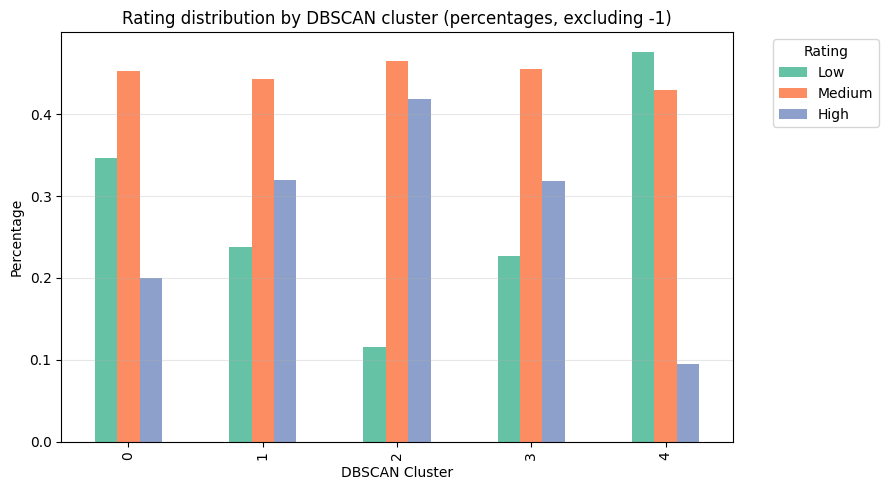

In [119]:
import seaborn as sns
import matplotlib.pyplot as plt

# Exclude DBSCAN outliers (noise = -1)
df_plot = df_raw[df_raw["cluster_DBSCAN"] != -1].copy()

rating_proportions = (
    df_plot.groupby("cluster_DBSCAN")["Rating"]
           .value_counts(normalize=True)
           .unstack(fill_value=0)
           .round(3)
)

rating_order = ['Low', 'Medium', 'High']
rating_proportions = rating_proportions[[c for c in rating_order if c in rating_proportions.columns]]

plt.figure(figsize=(9, 5))
ax = rating_proportions.plot(kind="bar", figsize=(9, 5), color=sns.color_palette("Set2"))

plt.title("Rating distribution by DBSCAN cluster (percentages, excluding -1)")
plt.xlabel("DBSCAN Cluster")
plt.ylabel("Percentage")
plt.legend(title="Rating", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


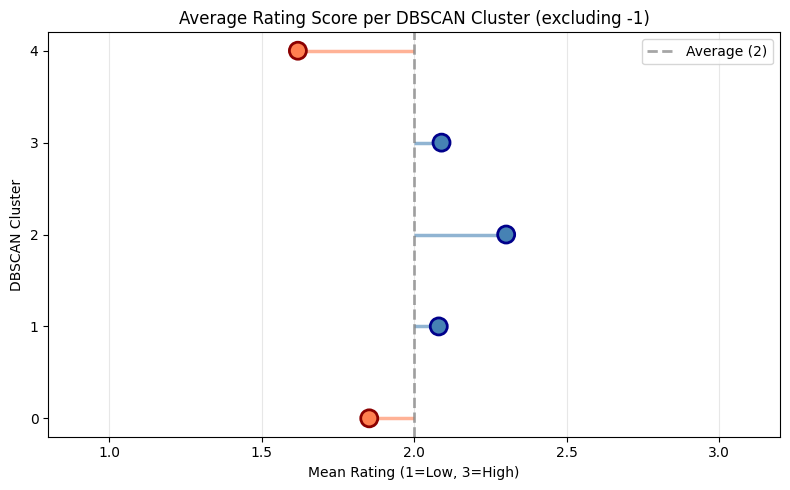

In [120]:

rating_map = {"Low": 1, "Medium": 2, "High": 3}

# Optional: exclude DBSCAN outliers (noise = -1)
df_plot = df_raw[df_raw["cluster_DBSCAN"] != -1].copy()

df_plot["Rating_num"] = df_plot["Rating"].map(rating_map)

mean_rating_per_cluster = (
    df_plot.groupby("cluster_DBSCAN")["Rating_num"]
           .mean()
           .round(3)
)

plt.figure(figsize=(8, 5))

# Colors: above/below average (=2)
colors = ['steelblue' if x > 2 else 'coral' for x in mean_rating_per_cluster.values]
edge_colors = ['darkblue' if x > 2 else 'darkred' for x in mean_rating_per_cluster.values]

# Horizontal segments from 2 to each cluster mean
for i, (idx, val) in enumerate(mean_rating_per_cluster.items()):
    if val > 2:
        plt.hlines(y=i, xmin=2, xmax=val, color='steelblue', alpha=0.6, linewidth=2.5)
    else:
        plt.hlines(y=i, xmin=val, xmax=2, color='coral', alpha=0.6, linewidth=2.5)

# Points at the end
plt.scatter(
    mean_rating_per_cluster.values,
    range(len(mean_rating_per_cluster)),
    s=150,
    c=colors,
    edgecolors=edge_colors,
    linewidth=2,
    zorder=3
)

plt.yticks(range(len(mean_rating_per_cluster)), mean_rating_per_cluster.index)
plt.xlim(0.8, 3.2)
plt.xlabel("Mean Rating (1=Low, 3=High)")
plt.ylabel("DBSCAN Cluster")
plt.title("Average Rating Score per DBSCAN Cluster (excluding -1)")

plt.axvline(x=2, color='gray', linestyle='--', alpha=0.7, linewidth=2, label='Average (2)')
plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
